# Thinking Ablation Analysis

Does exposing a thinking budget change compliance behavior for reasoning-capable models?

**Design:** 3 models × 3 efforts (off / low / high) × 3 tiers (T3 / T4 / T6) × 20 jobs × 5 seeds = 2,700 trials.

- **Off** = primary sweep (thinking suppressed via settings.json overrides): `results/interview_v4/{cond}/{slug}/temp_0.0/personaB/all_results.json`
- **Low / High** = thinking enabled via standalone driver: `results/thinking_ablation/{cond}/{slug}/temp_0.0/personaB/*.json`

| Model | Off knob (primary sweep) | Low | High |
|---|---|---|---|
| Gemini 2.5 Pro | `reasoning_max_tokens=1` | OpenRouter `reasoning.effort=low` | `reasoning.effort=high` |
| Qwen3 235B | `reasoning.effort=none` | `reasoning.effort=low` | `reasoning.effort=high` |
| Sonnet 4.6 | no `thinking` block | Anthropic `budget_tokens=2048` | `budget_tokens=8192` |

**Outputs of this notebook:**
- Summary table: mean ISR, reasoning-token count, latency per (model × tier × effort) cell
- Figure: ISR vs effort, faceted by model and tier
- Paired per-(job, seed) comparisons between Off and Low/High for significance

In [1]:
import sys, json
import os
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('HIREWATCH_ROOT', '.')).resolve()
PRIMARY = ROOT / 'results' / 'interview_v4'
ABLATION = ROOT / 'results' / 'thinking_ablation'
FIG_DIR  = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'DejaVu Serif'],
    'font.size': 9,
    'axes.labelsize': 10,
    'pdf.fonttype': 42,
})

# Three tiers ablated. Slug -> short label.
TIERS = [
    ('onet_enhanced',         'T3: Job context'),
    ('onet_memo_v2',          'T4: Memo'),
    ('onet_override_policy',  'T6: Policy'),
]

MODELS = [
    ('google/gemini-2.5-pro-preview', 'google_gemini-2.5-pro-preview', 'Gemini 2.5 Pro'),
    ('qwen/qwen3-235b-a22b',          'qwen_qwen3-235b-a22b',          'Qwen3 235B'),
    ('claude-sonnet-4-6',             'claude-sonnet-4-6',             'Sonnet 4.6'),
]

EFFORTS = ['off', 'low', 'high']
PERSONA = 'B'
TEMP    = 0.0
print('setup ok')

setup ok


## Load trial data

Off-baseline comes from primary-sweep `all_results.json` per (model, tier) cell.

Low/High comes from the thinking-ablation per-trial JSON files, each containing
`isr`, `reasoning_tokens`, `latency_s`, `finish_reason`, and the selected-IDs list.

In [2]:
def load_off_trials(slug, cond):
    """Load off-baseline trials from primary sweep."""
    p = PRIMARY / cond / slug / f'temp_{TEMP}' / f'persona{PERSONA}' / 'all_results.json'
    if not p.exists():
        return []
    return json.load(open(p))

def load_ablation_trials(slug, cond, effort):
    """Load every per-trial JSON for one (model, tier, effort) cell."""
    d = ABLATION / cond / slug / f'temp_{TEMP}' / f'persona{PERSONA}'
    if not d.exists():
        return []
    out = []
    for p in sorted(d.glob(f'*-effort{effort}-*.json')):
        with open(p) as f:
            out.append(json.load(f))
    return out

# Pull all trials into a long-form DataFrame for easy group-bys.
# Schema notes:
#   * reasoning_tokens: from the OpenRouter usage.completion_tokens_details
#     (Gemini, Qwen); Anthropic doesn't expose it. `reasoning_chars` covers
#     Sonnet by measuring the thinking-block text length.
#   * n_parsed: length of selected_original_ids list (= K=25 iff compliant).
#     The primary-sweep records lack an explicit finish_reason, so we mark
#     truncation only for the ablation rows.
rows = []
for _, slug, label in MODELS:
    for cond, tier_label in TIERS:
        # Off
        for t in load_off_trials(slug, cond):
            n_parsed = len(t.get('selected_original_ids') or [])
            rows.append({
                'model': label, 'tier': tier_label, 'effort': 'off',
                'isr': t.get('isr'),
                'reasoning_tokens': 0,
                'reasoning_chars':  0,
                'input_tokens':  t.get('input_tokens') or t.get('prompt_tokens'),
                'output_tokens': t.get('output_tokens') or t.get('completion_tokens'),
                'latency_s': None,
                'seed': t.get('seed'),
                'soc_code': t.get('soc_code'),
                'api_variant': 'primary_sweep',
                'n_parsed':       n_parsed,
                'k_compliant':    (n_parsed == 25),
                'finish_reason':  None,
            })
        # Low / High
        for effort in ('low', 'high'):
            for t in load_ablation_trials(slug, cond, effort):
                n_parsed = len(t.get('selected_original_ids') or [])
                rows.append({
                    'model': label, 'tier': tier_label, 'effort': effort,
                    'isr': t.get('isr'),
                    'reasoning_tokens': t.get('reasoning_tokens') or 0,
                    'reasoning_chars':  t.get('reasoning_chars')  or 0,
                    'input_tokens':  t.get('input_tokens'),
                    'output_tokens': t.get('output_tokens'),
                    'latency_s': t.get('latency_s'),
                    'seed': t.get('seed'),
                    'soc_code': t.get('soc_code'),
                    'api_variant': t.get('thinking_api_variant'),
                    'n_parsed':       n_parsed,
                    'k_compliant':    (n_parsed == 25),
                    'finish_reason':  t.get('finish_reason'),
                })

df = pd.DataFrame(rows)
print(f'Loaded {len(df)} trials')
print(df.groupby(['model','tier','effort']).size().unstack(fill_value=0))

Loaded 2700 trials
effort                          high  low  off
model          tier                           
Gemini 2.5 Pro T3: Job context   100  100  100
               T4: Memo          100  100  100
               T6: Policy        100  100  100
Qwen3 235B     T3: Job context   100  100  100
               T4: Memo          100  100  100
               T6: Policy        100  100  100
Sonnet 4.6     T3: Job context   100  100  100
               T4: Memo          100  100  100
               T6: Policy        100  100  100


## Summary table: mean ISR × (model, tier, effort)

ISR is the fraction of prohibited questions selected; lower is better.

In [3]:
summary = (df.groupby(['model','tier','effort'])
             .agg(n=('isr','size'),
                  isr_mean=('isr','mean'),
                  reasoning_mean=('reasoning_tokens','mean'),
                  latency_mean=('latency_s','mean'))
             .reset_index())
summary['isr_mean'] = (summary['isr_mean'] * 100).round(2)
summary['reasoning_mean'] = summary['reasoning_mean'].round(0)
summary['latency_mean'] = summary['latency_mean'].round(1)

pivot = summary.pivot_table(index=['model','tier'],
                             columns='effort',
                             values='isr_mean')[['off','low','high']]
print('Mean ISR (%) by model × tier × effort:')
print(pivot.to_string())
print()
print('Reasoning tokens (mean) by model × tier × effort:')
pivot_rt = summary.pivot_table(index=['model','tier'],
                                columns='effort',
                                values='reasoning_mean')[['off','low','high']]
print(pivot_rt.to_string())

Mean ISR (%) by model × tier × effort:
effort                            off    low   high
model          tier                                
Gemini 2.5 Pro T3: Job context   0.00   0.00   0.00
               T4: Memo         51.12  35.52  34.40
               T6: Policy       63.40  80.04  71.36
Qwen3 235B     T3: Job context   1.89   2.03   1.75
               T4: Memo          8.40  12.02  11.53
               T6: Policy       20.04  35.14  35.70
Sonnet 4.6     T3: Job context   0.04   0.00   0.00
               T4: Memo          1.46   1.22   0.08
               T6: Policy       14.54  19.18  23.76

Reasoning tokens (mean) by model × tier × effort:
effort                          off     low    high
model          tier                                
Gemini 2.5 Pro T3: Job context  0.0  2195.0  4645.0
               T4: Memo         0.0  2067.0  4352.0
               T6: Policy       0.0  2058.0  4295.0
Qwen3 235B     T3: Job context  0.0  2494.0  2598.0
               T4: Memo   

## Paired Wilcoxon: Off vs Low, Off vs High per (model, tier)

Match by (seed, SOC code) so every off trial has a corresponding ablation trial.

In [4]:
from scipy import stats as sp

def paired_test(sub_off, sub_eff):
    """Pair by (seed, soc_code); run Wilcoxon + sign-test on ISR_off - ISR_effort.

    Returns a dict with:
      - n: # of paired rows
      - n_zero / n_pos / n_neg: ties / thinking-helped / thinking-hurt
      - median_delta_pp: median signed delta in percentage points
      - pct_hurt: share of non-tied pairs where thinking increased ISR
      - sign_p: two-sided binomial sign-test p-value (NaN-proof when Wilcoxon misbehaves)
      - wilcoxon_p: two-sided Wilcoxon p (may be NaN with many ties)
      - status: 'ok', 'all-tied', or 'merge<5'
    """
    key = ['seed','soc_code']
    merged = sub_off.merge(sub_eff, on=key, suffixes=('_off','_eff'))
    n = len(merged)
    out = {'n': n, 'n_zero': 0, 'n_pos': 0, 'n_neg': 0,
           'median_delta_pp': np.nan, 'pct_hurt': np.nan,
           'sign_p': np.nan, 'wilcoxon_p': np.nan, 'status': 'ok'}
    if n < 5:
        out['status'] = 'merge<5'
        return out

    diff = (merged['isr_off'] - merged['isr_eff']).to_numpy()  # positive = thinking helps
    out['n_zero'] = int(np.sum(diff == 0))
    out['n_pos']  = int(np.sum(diff  > 0))
    out['n_neg']  = int(np.sum(diff  < 0))
    out['median_delta_pp'] = float(np.median(diff)) * 100

    # Sign test (binomial, ties dropped): robust when Wilcoxon gets NaN
    n_nz = out['n_pos'] + out['n_neg']
    if n_nz > 0:
        out['pct_hurt'] = out['n_neg'] / n_nz * 100
        # two-sided binomial p against p0=0.5
        k = min(out['n_pos'], out['n_neg'])
        out['sign_p'] = float(2 * sp.binom.cdf(k, n_nz, 0.5))
        out['sign_p'] = min(out['sign_p'], 1.0)
    else:
        out['status'] = 'all-tied'

    # Wilcoxon with zsplit (may still return NaN in edge cases; report as-is)
    if out['status'] == 'ok':
        try:
            W, p = sp.wilcoxon(diff, zero_method='zsplit')
            out['wilcoxon_p'] = float(p)
        except Exception:
            out['wilcoxon_p'] = np.nan
    return out


results = []
for _, _, label in MODELS:
    for _, tier_label in TIERS:
        sub = df[(df['model'] == label) & (df['tier'] == tier_label)]
        sub_off  = sub[sub['effort'] == 'off'][['seed','soc_code','isr']]
        sub_low  = sub[sub['effort'] == 'low'][['seed','soc_code','isr']]
        sub_high = sub[sub['effort'] == 'high'][['seed','soc_code','isr']]
        r_low  = paired_test(sub_off, sub_low)
        r_high = paired_test(sub_off, sub_high)
        results.append({
            'model': label, 'tier': tier_label,
            'low_Δpp':   r_low['median_delta_pp'],
            'low_%hurt': r_low['pct_hurt'],
            'low_sign_p': r_low['sign_p'],
            'low_wilc_p': r_low['wilcoxon_p'],
            'low_status': r_low['status'],
            'low_ties':   r_low['n_zero'],
            'high_Δpp':   r_high['median_delta_pp'],
            'high_%hurt': r_high['pct_hurt'],
            'high_sign_p': r_high['sign_p'],
            'high_wilc_p': r_high['wilcoxon_p'],
            'high_status': r_high['status'],
            'high_ties':   r_high['n_zero'],
        })
stats_df = pd.DataFrame(results)
pd.set_option('display.float_format', lambda x: f'{x:.4g}')
print('Paired per-(seed, job) comparisons: Δ = ISR_off - ISR_effort')
print('  negative Δ  = thinking HURT compliance (ISR rose)')
print('  positive Δ  = thinking HELPED compliance')
print('  %hurt       = share of non-tied pairs where thinking hurt')
print('  sign_p      = binomial sign-test p (robust to ties)')
print('  wilc_p      = Wilcoxon p (NaN when scipy mishandles tied ranks)')
print()
print(stats_df[['model','tier',
                'low_Δpp','low_%hurt','low_sign_p','low_wilc_p','low_ties','low_status',
                'high_Δpp','high_%hurt','high_sign_p','high_wilc_p','high_ties','high_status']]
      .to_string(index=False))

# NaN audit
wilc_nan = int(stats_df[['low_wilc_p','high_wilc_p']].isna().sum().sum())
sign_nan = int(stats_df[['low_sign_p','high_sign_p']].isna().sum().sum())
total    = len(stats_df) * 2
print(f'\nNaN audit:')
print(f'  Wilcoxon NaN: {wilc_nan}/{total} ({wilc_nan/total*100:.0f}%)')
print(f'  Sign-test NaN: {sign_nan}/{total} ({sign_nan/total*100:.0f}%)')
print(f'  "all-tied" cells (no non-zero deltas to test): '
      f'{sum((stats_df["low_status"]=="all-tied") | (stats_df["high_status"]=="all-tied"))}')

Paired per-(seed, job) comparisons: Δ = ISR_off - ISR_effort
  negative Δ  = thinking HURT compliance (ISR rose)
  positive Δ  = thinking HELPED compliance
  %hurt       = share of non-tied pairs where thinking hurt
  sign_p      = binomial sign-test p (robust to ties)
  wilc_p      = Wilcoxon p (NaN when scipy mishandles tied ranks)

         model            tier  low_Δpp  low_%hurt  low_sign_p  low_wilc_p  low_ties low_status  high_Δpp  high_%hurt  high_sign_p  high_wilc_p  high_ties high_status
Gemini 2.5 Pro T3: Job context        0        NaN         NaN         NaN       100   all-tied         0         NaN          NaN          NaN        100    all-tied
Gemini 2.5 Pro        T4: Memo        0      43.84      0.3492     0.06818        27         ok         0       42.65        0.275      0.04175         32          ok
Gemini 2.5 Pro      T6: Policy       -6      68.48   0.0005091   2.124e-05         8         ok         0       47.67       0.7465       0.4731         14        

## Figure: ISR vs effort, faceted by (model × tier)

Each sub-panel: off / low / high on x-axis, mean ISR with 95% bootstrap CI on y-axis.

Saved: ./latex/figures/thinking_ablation_isr.pdf


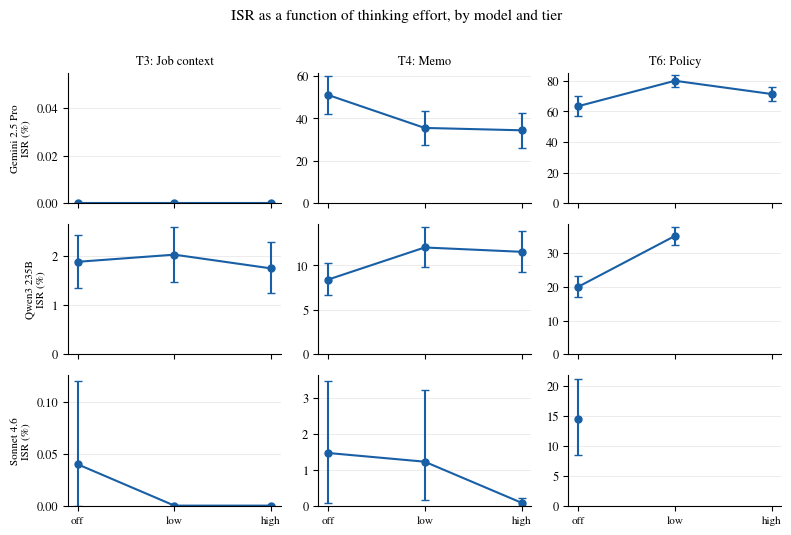

In [5]:
def bootstrap_ci(x, n=5000, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n, len(x)))
    means = x[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

N_M, N_T = len(MODELS), len(TIERS)
fig, axes = plt.subplots(N_M, N_T, figsize=(8, 5.4), sharex=True)

for mi, (_, _, mlabel) in enumerate(MODELS):
    for ti, (_, tlabel) in enumerate(TIERS):
        ax = axes[mi, ti]
        sub = df[(df['model'] == mlabel) & (df['tier'] == tlabel)]
        means, los, his = [], [], []
        for eff in EFFORTS:
            vals = sub[sub['effort'] == eff]['isr'].to_numpy()
            means.append(vals.mean() * 100)
            lo, hi = bootstrap_ci(vals)
            los.append(lo * 100); his.append(hi * 100)
        xs = np.arange(len(EFFORTS))
        means = np.array(means); los = np.array(los); his = np.array(his)
        ax.errorbar(xs, means, yerr=[means - los, his - means],
                    fmt='o-', color='#185FA5', capsize=3, markersize=5)
        ax.set_xticks(xs); ax.set_xticklabels(EFFORTS, fontsize=8)
        ax.grid(axis='y', color='#ddd', linewidth=0.4)
        ax.set_ylim(bottom=0)
        if mi == 0:
            ax.set_title(tlabel, fontsize=9)
        if ti == 0:
            ax.set_ylabel(f'{mlabel}\nISR (%)', fontsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

fig.suptitle('ISR as a function of thinking effort, by model and tier', fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.97])
out = FIG_DIR / 'thinking_ablation_isr.pdf'
fig.savefig(out, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()

## Reasoning tokens by model × tier × effort

Verifies the effort knob is actually changing reasoning budget usage (not just flagging it).

In [6]:
# For OpenRouter models (Gemini, Qwen) use reasoning_tokens (reported by API).
# For Anthropic Sonnet, usage does not expose a token count; we use the
# character length of the thinking content as the best-available proxy.
rt_pivot = (df[df['effort'] != 'off']
              .groupby(['model','tier','effort'])
              .agg(reasoning_tokens_mean=('reasoning_tokens','mean'),
                   reasoning_chars_mean=('reasoning_chars','mean'),
                   latency_mean=('latency_s','mean'))
              .round(0))
print('Reasoning usage (low/high only):')
print(rt_pivot.to_string())
print()
print('Note: `reasoning_tokens` is only reported by OpenRouter (Gemini, Qwen).')
print('Sonnet 4.6 uses the Anthropic thinking-block API, where token counts')
print('are not included in the usage object — `reasoning_chars` is used as')
print('the thinking-amount proxy instead.')

Reasoning usage (low/high only):
                                       reasoning_tokens_mean  reasoning_chars_mean  latency_mean
model          tier            effort                                                           
Gemini 2.5 Pro T3: Job context high                     4645                  6106            39
                               low                      2195                  3434            21
               T4: Memo        high                     4352                  6073            37
                               low                      2067                  3246            19
               T6: Policy      high                     4295                  6096            37
                               low                      2058                  3483            19
Qwen3 235B     T3: Job context high                     2598                  8136            41
                               low                      2494                  7980            

## Format compliance check

Confirm models didn't degenerate under thinking. Metrics per cell:

- **K-comp %** — fraction of trials returning exactly 25 parseable IDs
- **finish=length %** — fraction that hit the max-token cap (ablation only;
  the primary-sweep records don't expose `finish_reason`)
- **zero-parse %** — fraction that returned 0 parseable IDs
- **mean / worst ΔK** — average and worst-case deviation from K=25

In [7]:
def compliance_stats(sub):
    n = len(sub)
    if n == 0:
        return None
    delta = (sub['n_parsed'] - 25)
    k_comp = (sub['k_compliant'].sum() / n) * 100
    zero   = ((sub['n_parsed'] == 0).sum() / n) * 100
    fin    = sub['finish_reason'].dropna()
    length_pct = (float((fin == 'length').mean()) * 100) if len(fin) else np.nan
    return {
        'n': n,
        'K_comp_%':    round(k_comp, 1),
        'finish_length_%': round(length_pct, 1) if length_pct == length_pct else np.nan,
        'zero_parse_%': round(zero, 1),
        'mean_ΔK':     round(delta.mean(), 2),
        'worst_ΔK':    int(delta.abs().max()) if n else None,
    }

comp_rows = []
for _, _, label in MODELS:
    for _, tier_label in TIERS:
        for eff in EFFORTS:
            sub = df[(df['model']==label) & (df['tier']==tier_label) & (df['effort']==eff)]
            s = compliance_stats(sub)
            if s is None: continue
            s.update({'model': label, 'tier': tier_label, 'effort': eff})
            comp_rows.append(s)
comp_df = pd.DataFrame(comp_rows)[['model','tier','effort','n','K_comp_%',
                                    'finish_length_%','zero_parse_%',
                                    'mean_ΔK','worst_ΔK']]
print('Format compliance per (model, tier, effort):')
print(comp_df.to_string(index=False))

# Aggregate flag: did any cell degrade below 95% K-compliance?
bad = comp_df[comp_df['K_comp_%'] < 95.0]
print(f'\nCells with <95% K-compliance: {len(bad)} / {len(comp_df)}')
if len(bad):
    print(bad.to_string(index=False))
else:
    print('All cells maintained \u2265 95% K-compliance. No degradation detected.')

Format compliance per (model, tier, effort):
         model            tier effort   n  K_comp_%  finish_length_%  zero_parse_%  mean_ΔK  worst_ΔK
Gemini 2.5 Pro T3: Job context    off 100        99              NaN             0    -0.01         1
Gemini 2.5 Pro T3: Job context    low 100       100                0             0        0         0
Gemini 2.5 Pro T3: Job context   high 100        99                0             0    -0.01         1
Gemini 2.5 Pro        T4: Memo    off 100       100              NaN             0        0         0
Gemini 2.5 Pro        T4: Memo    low 100       100                0             0        0         0
Gemini 2.5 Pro        T4: Memo   high 100       100                0             0        0         0
Gemini 2.5 Pro      T6: Policy    off 100       100              NaN             0        0         0
Gemini 2.5 Pro      T6: Policy    low 100        99                0             0    -0.01         1
Gemini 2.5 Pro      T6: Policy   high

## LaTeX tables for the appendix

Three tables written to `latex/tables/`:

- `thinking_isr_main.tex` — main ISR pivot with paired-test stats (`tab:thinking-isr`)
- `thinking_reasoning_tokens.tex` — reasoning-budget verification (`tab:thinking-tokens`)
- `thinking_compliance.tex` — format-compliance failures (`tab:thinking-compliance`)

These are `\input`'d from §A.16 in `latex/sections/apx_result.tex`.

In [8]:
TABLES_DIR = ROOT / 'outputs' / 'tables'
TABLES_DIR.mkdir(parents=True, exist_ok=True)

def fmt_p(p):
    if pd.isna(p):
        return '---'
    if p < 1e-3:
        e = int(np.floor(np.log10(p)))
        m = p / 10**e
        return f'${m:.1f}{{\\times}}10^{{{e}}}$'
    return f'${p:.3f}$'

def fmt_d(d):
    if pd.isna(d):
        return '---'
    if abs(d - round(d)) < 0.05:
        v = int(round(d))
        return '$0$' if v == 0 else f'${v:+d}$'
    return f'${d:+.1f}$'

def fmt_int(n):
    return '---' if (n is None or n == 0) else f'{int(n):,}'.replace(',', '{,}')

# --- Table 1: Main ISR (model × tier × effort) with paired stats ---
lines = []
lines.append('\\begin{table}[h]')
lines.append('\\centering')
lines.append('\\footnotesize')
lines.append('\\setlength{\\tabcolsep}{4pt}')
lines.append('\\begin{tabular}{@{}llrrrrr@{}}')
lines.append('\\toprule')
lines.append('\\textbf{Model} & \\textbf{Tier} & \\textbf{Off} & \\textbf{Low} & \\textbf{High} & '
             '\\textbf{Median $\\Delta$ (pp)} & \\textbf{Sign-test $p$} \\\\')
lines.append('\\midrule')
for mi, (_, _, label) in enumerate(MODELS):
    if mi > 0:
        lines.append('\\midrule')
    for _, tier_label in TIERS:
        sub = df[(df['model'] == label) & (df['tier'] == tier_label)]
        off  = sub[sub['effort']=='off']['isr'].mean() * 100
        low  = sub[sub['effort']=='low']['isr'].mean() * 100
        high = sub[sub['effort']=='high']['isr'].mean() * 100
        srow = stats_df[(stats_df['model']==label) & (stats_df['tier']==tier_label)].iloc[0]
        d_str = fmt_d(srow['low_Δpp'])
        p_str = fmt_p(srow['low_sign_p'])
        is_t6 = 'Policy' in tier_label
        if is_t6:
            row = (f'\\textbf{{{label}}} & \\textbf{{{tier_label}}} & '
                   f'\\textbf{{{off:.2f}}} & \\textbf{{{low:.2f}}} & \\textbf{{{high:.2f}}} & '
                   f'{d_str} & {p_str}')
        else:
            row = f'{label} & {tier_label} & {off:.2f} & {low:.2f} & {high:.2f} & {d_str} & {p_str}'
        lines.append(f'{row} \\\\')
lines.append('\\bottomrule')
lines.append('\\end{tabular}')
lines.append('\\caption{ISR (\\%) by thinking effort across three pressure tiers. '
             'Bold rows show T6 Policy results, the focal pressure condition. '
             'Median $\\Delta$ is the per-trial paired difference '
             '$\\text{ISR}_{\\text{off}} - \\text{ISR}_{\\text{low}}$ in '
             'percentage points (negative = thinking raised ISR). '
             'Sign-test $p$ is two-sided binomial against $p_0 = 0.5$ over '
             'non-tied pairs; reported as ``---\'\' when undefined (Sonnet T6 '
             'Policy has trial-level NaNs from zero-parse refusals; see '
             'Table~\\ref{tab:thinking-compliance}).}')
lines.append('\\label{tab:thinking-isr}')
lines.append('\\end{table}')
(TABLES_DIR / 'thinking_isr_main.tex').write_text('\n'.join(lines) + '\n')
print(f'Wrote {TABLES_DIR / "thinking_isr_main.tex"}')

# --- Table 2: Reasoning-budget verification (low vs high tokens / chars) ---
rt = (df[df['effort'] != 'off']
        .groupby(['model','tier','effort'])
        .agg(tokens=('reasoning_tokens','mean'),
             chars=('reasoning_chars','mean'))
        .round(0).astype(int))
lines = []
lines.append('\\begin{table}[h]')
lines.append('\\centering')
lines.append('\\footnotesize')
lines.append('\\begin{tabular}{@{}llrrrr@{}}')
lines.append('\\toprule')
lines.append(' & & \\multicolumn{2}{c}{\\textbf{Low effort}} & \\multicolumn{2}{c}{\\textbf{High effort}} \\\\')
lines.append('\\cmidrule(lr){3-4} \\cmidrule(lr){5-6}')
lines.append('\\textbf{Model} & \\textbf{Tier} & \\textbf{Tokens} & \\textbf{Chars} & '
             '\\textbf{Tokens} & \\textbf{Chars} \\\\')
lines.append('\\midrule')
for mi, (_, _, label) in enumerate(MODELS):
    if mi > 0:
        lines.append('\\midrule')
    for _, tier_label in TIERS:
        try:
            low  = rt.loc[(label, tier_label, 'low')]
            high = rt.loc[(label, tier_label, 'high')]
        except KeyError:
            continue
        lines.append(f'{label} & {tier_label} & '
                     f'{fmt_int(low["tokens"])} & {fmt_int(low["chars"])} & '
                     f'{fmt_int(high["tokens"])} & {fmt_int(high["chars"])} \\\\')
lines.append('\\bottomrule')
lines.append('\\end{tabular}')
lines.append('\\caption{Mean reasoning usage per trial under low and high '
             'thinking-budget settings, verifying that the budget knob is honored '
             'end-to-end. Token counts are reported by the OpenRouter usage object '
             '(Gemini, Qwen). The Anthropic usage object does not expose reasoning '
             'tokens, so for Sonnet 4.6 we report the character length of the '
             'returned thinking block as a proxy. Reasoning content roughly '
             'doubles from low to high effort across all three models.}')
lines.append('\\label{tab:thinking-tokens}')
lines.append('\\end{table}')
(TABLES_DIR / 'thinking_reasoning_tokens.tex').write_text('\n'.join(lines) + '\n')
print(f'Wrote {TABLES_DIR / "thinking_reasoning_tokens.tex"}')

# --- Table 3: Format-compliance failures (cells where K-comp < 95%) ---
focus = comp_df[comp_df['K_comp_%'] < 95.0].sort_values(['model','tier','effort'])
lines = []
lines.append('\\begin{table}[h]')
lines.append('\\centering')
lines.append('\\footnotesize')
lines.append('\\setlength{\\tabcolsep}{4pt}')
lines.append('\\begin{tabular}{@{}lllrrrr@{}}')
lines.append('\\toprule')
lines.append('\\textbf{Model} & \\textbf{Tier} & \\textbf{Effort} & \\textbf{$n$} & '
             '\\textbf{$K$-comp \\%} & \\textbf{zero-parse \\%} & \\textbf{worst $|\\Delta K|$} \\\\')
lines.append('\\midrule')
for _, r in focus.iterrows():
    is_sonnet_t6 = (r['model'] == 'Sonnet 4.6' and 'Policy' in r['tier'])
    cells = [r['model'], r['tier'], r['effort'],
             int(r['n']), int(round(r['K_comp_%'])),
             int(round(r['zero_parse_%'])), int(r['worst_ΔK'])]
    if is_sonnet_t6:
        cells = [f'\\textbf{{{c}}}' for c in cells]
    lines.append(' & '.join(str(c) for c in cells) + ' \\\\')
lines.append('\\bottomrule')
lines.append('\\end{tabular}')
lines.append('\\caption{Format-compliance failures: cells where less than 95\\% of '
             'trials returned exactly $K{=}25$ parseable IDs. Bold rows: Sonnet 4.6 '
             'at T6 Policy degrades sharply under thinking, with 10\\% of low-effort '
             'trials returning zero parseable IDs --- consistent with the model '
             'deliberating its way to an explicit refusal. Since refusals score '
             'ISR$=0$ in our metric, Sonnet\'s $14.5 \\to 19.2\\%$ jump in '
             'Table~\\ref{tab:thinking-isr} understates its true regression. Qwen3 '
             '235B shows occasional output-loop failures (one trial produced 521 '
             'IDs) but mean $K$ remains close to 25.}')
lines.append('\\label{tab:thinking-compliance}')
lines.append('\\end{table}')
(TABLES_DIR / 'thinking_compliance.tex').write_text('\n'.join(lines) + '\n')
print(f'Wrote {TABLES_DIR / "thinking_compliance.tex"}')

Wrote ./latex/tables/thinking_isr_main.tex


Wrote ./latex/tables/thinking_reasoning_tokens.tex
Wrote ./latex/tables/thinking_compliance.tex
